# The incomplete gamma functions: which one to call, and their gradients

The regularized incomplete gamma functions

$$P(a, x) = \frac{\gamma(a, x)}{\Gamma(a)}, \qquad Q(a, x) = 1 - P(a, x)$$

are the CDF and survival function of a Gamma(a, 1) variable. chebax names
every function the same way: one name that takes any shape of a, and one
name per path for when you already know which one you want.

| call | a is ... | gradients |
|---|---|---|
| `gammainc(a, x)` | anything: one value runs `_scalar`, an array runs `_array` | in a and x |
| `gammainc_scalar(a, x)` | one traceable value for the whole call | in a and x |
| `gammainc_array(a, x)` | one value per element, broadcast with x | in each element's a, and x |
| `gammainc_frozen(a)(x)` | a concrete number; returns a cached callable of x | in x |
| `pergroup(gammainc, group_idx)(a_groups, x)` | one value per group, groups fixed | in each group's a, and x |

The same names exist for Q (`gammaincc...`) and for the logs
(`log_gammainc...`, `log_gammaincc...`, which stay finite where P or Q
underflows; they have no frozen form). The inverses `gammaincinv`,
`gammainccinv` and `chi2inv` are covered at the end. Everything accepts
a ≥ 0.1 and x ≥ 0.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import scipy.special as sps
from jax.scipy.optimize import minimize

jax.config.update("jax_enable_x64", True)

import chebax


def gamma_pdf(a, x):
    """The Gamma(a, 1) density, the exact x-derivative of P."""
    return np.exp((a - 1) * np.log(x) - x - sps.gammaln(a))

## The plain name

`gammainc(a, x)` is the one to reach for. With one value of a it runs
the scalar path; with an array of a it runs the per-element path. The
choice is made from the shape of a, which jax knows at trace time, so it
costs nothing at run time and works the same under `jit` and `grad`.

In [2]:
x = jnp.asarray([0.3, 2.0, 9.0, 60.0])
print("one a:   ", np.asarray(chebax.gammainc(2.5, x)))
a = jnp.asarray([0.5, 2.5, 7.0, 40.0])
print("a per x: ", np.asarray(chebax.gammainc(a, x)))
print("scipy:   ", sps.gammainc(np.asarray(a), np.asarray(x)))

# gradients in both arguments, for either shape of a
print(jax.grad(chebax.gammainc, argnums=(0, 1))(2.5, 3.0))
print(jax.grad(lambda a, x: chebax.gammainc(a, x).sum(), argnums=(0, 1))(a, x))

one a:    [0.01199676 0.45058405 0.9970536  1.        ]


a per x:  [0.56142197 0.45058405 0.79321916 0.99745181]
scipy:    [0.56142197 0.45058405 0.79321916 0.99745181]


E1102 17:20:02.321555 2465062 algebraic_simplifier.cc:10574] Algebraic simplifier is likely stuck in a circular simplification loop and ran for 50 runs on computation region_7.31


(Array(-0.22754855, dtype=float64, weak_type=True), Array(0.19460869, dtype=float64, weak_type=True))


(Array([-0.77057035, -0.27455132, -0.10549943, -0.00116821], dtype=float64), Array([0.76309058, 0.28795182, 0.09109032, 0.00095641], dtype=float64))


## One traced a: `gammainc_scalar`

When a is one value, such as a latent shape or a fitted dispersion, the
scalar path collapses the tables' a-axis once per call and evaluates a 1-D
series over x. a may be traced, so `jit` and `grad` work in both
arguments:

- `gammainc_scalar(a, x)` is P and `gammaincc_scalar(a, x)` is Q;
- `log_gammainc_scalar(a, x)` is ln P and `log_gammaincc_scalar(a, x)` is ln Q.

In [3]:
a0, x0 = 2.5, 3.0
print("P :", float(chebax.gammainc_scalar(a0, x0)), " scipy:", sps.gammainc(a0, x0))

dPda, dPdx = jax.grad(chebax.gammainc_scalar, argnums=(0, 1))(a0, x0)

# references: a central difference of scipy in a, the density in x
h = 1e-6
fd_a = (sps.gammainc(a0 + h, x0) - sps.gammainc(a0 - h, x0)) / (2 * h)
print(f"dP/da: {float(dPda):.12f}   central difference: {fd_a:.12f}")
print(f"dP/dx: {float(dPdx):.12f}   density:            {gamma_pdf(a0, x0):.12f}")

P : 0.6937810815867214  scipy: 0.6937810815867212


E1102 17:20:06.757176 2465062 algebraic_simplifier.cc:10574] Algebraic simplifier is likely stuck in a circular simplification loop and ran for 50 runs on computation region_7.31


dP/da: -0.227548551278   central difference: -0.227548550891
dP/dx: 0.194608693319   density:            0.194608693319


Inside `jit`, a is an argument like any other. Here dP/da is evaluated
along a curve of a, with x fixed:

In [4]:
dP_da = jax.jit(jax.vmap(jax.grad(chebax.gammainc_scalar), in_axes=(0, None)))
a_grid = jnp.linspace(0.5, 20.0, 5)
print(np.asarray(dP_da(a_grid, 5.0)))

[-5.84336226e-03 -1.78694260e-01 -2.13846776e-02 -2.27995868e-04
 -4.92026840e-07]


Asking the scalar path for more than one a is an error, and the message
names the per-element path:

In [5]:
try:
    chebax.gammainc_scalar(jnp.asarray([1.0, 2.0]), jnp.asarray([0.5, 0.5]))
except ValueError as e:
    print(e)

gammainc_scalar takes a as a scalar (uniform per call), got shape (2,). For a per element use chebax.gammainc_array; for one parameter set per group use chebax.pergroup(gammainc_scalar, group_idx).


### The log forms

ln P and ln Q are computed directly, not as the log of P or Q, so they
stay finite where P or Q underflows. This matters in likelihoods: the
log survival function of an observation censored far in the tail.

In [6]:
for xq in (50.0, 1000.0):
    with np.errstate(divide="ignore"):
        naive = np.log(sps.gammaincc(2.5, xq))
    print(f"x = {xq:6.0f}: log_gammaincc = {float(chebax.log_gammaincc(2.5, xq)):12.4f}"
          f"   log(scipy gammaincc) = {naive}")

print("d ln Q/da at (2.5, 1000):", float(jax.grad(chebax.log_gammaincc)(2.5, 1000.0)))

x =     50: log_gammaincc =     -44.3868   log(scipy gammaincc) = -44.386801168872644


x =   1000: log_gammaincc =    -989.9216   log(scipy gammaincc) = -inf


E1102 17:20:12.531322 2465062 algebraic_simplifier.cc:10574] Algebraic simplifier is likely stuck in a circular simplification loop and ran for 50 runs on computation region_8.31


d ln Q/da at (2.5, 1000): 6.205599136589516


## A different a on every element: `gammainc_array`

In a Gamma regression the shape can depend on covariates, so every
observation has its own a. The per-element path evaluates one small 2-D
Chebyshev patch per element instead of collapsing a table per call. a and
x broadcast together like any numpy operation.

In [7]:
a = jnp.asarray([[0.5], [2.5], [40.0]])  # shape (3, 1)
x = jnp.asarray([0.3, 2.0, 9.0, 60.0])  # shape (4,)
Pe = chebax.gammainc_array(a, x)  # shape (3, 4)
print(Pe.shape)
print(np.max(np.abs(np.asarray(Pe) - sps.gammainc(np.asarray(a), np.asarray(x)))))

(3, 4)
2.220446049250313e-16


### Gradients with a per element

The function is elementwise, so the gradient of the sum gives every
element's own derivative, in a and in x, in one reverse pass. Forward
mode (`jax.jvp`) gives the same numbers.

In [8]:
rng = np.random.default_rng(0)
a = jnp.asarray(np.exp(rng.uniform(np.log(0.1), np.log(100.0), 6)))
x = jnp.asarray(rng.gamma(np.asarray(a)))

dPda, dPdx = jax.grad(lambda a, x: chebax.gammainc_array(a, x).sum(), argnums=(0, 1))(a, x)
_, dPda_fwd = jax.jvp(chebax.gammainc_array, (a, x), (jnp.ones_like(a), jnp.zeros_like(x)))

fd_a = (sps.gammainc(np.asarray(a) + h, x) - sps.gammainc(np.asarray(a) - h, x)) / (2 * h)
print("a        :", np.round(np.asarray(a), 4))
print("dP/da    :", np.asarray(dPda))
print("forward  :", np.asarray(dPda_fwd))
print("central d:", fd_a)
print("max |dP/dx - density|:", np.max(np.abs(np.asarray(dPdx) - gamma_pdf(np.asarray(a), np.asarray(x)))))

a        : [ 8.1449  0.6447  0.1327  0.1121 27.5303 54.7352]
dP/da    : [-0.05638937 -0.64214602 -1.59026755 -0.98977939 -0.06943322 -0.05382568]
forward  : [-0.05638937 -0.64214602 -1.59026755 -0.98977939 -0.06943322 -0.05382568]
central d: [-0.05638937 -0.64214602 -1.59026755 -0.98977939 -0.06943322 -0.05382568]
max |dP/dx - density|: 3.400058012914542e-15


`jax.vmap(chebax.gammainc_scalar)` also accepts an array of a and gives
the same values. It rebuilds the tables for every element, though, and
`experiments/22` measured its value_and_grad at 73-77x the cost of
`gammainc_array` on a CPU core (54x on a laptop GPU).

In [9]:
same = jax.vmap(chebax.gammainc_scalar)(a, x)
print("max |vmap(gammainc_scalar) - gammainc_array|:",
      float(jnp.max(jnp.abs(same - chebax.gammainc_array(a, x)))))

max |vmap(gammainc_scalar) - gammainc_array|: 6.661338147750939e-16


Values outside the domain do not raise, since a can be traced: a < 0.1
(and a = nan or inf) gives nan, x ≤ 0 gives P = 0, and x = inf gives
P = 1.

In [10]:
print(np.asarray(chebax.gammainc_array(jnp.asarray([0.05, 2.0, 2.0, 2.0]),
                                       jnp.asarray([1.0, -1.0, 0.0, jnp.inf]))))

[nan  0.  0.  1.]


### Example: a censored Gamma regression

The shape of each observation is $\alpha_i = \exp(b_0 + b_1 z_i)$ for
a covariate $z_i$, with rate r. Observations above a detection limit c
are censored. They contribute ln Q(α_i, r c) to the log-likelihood. The
plain `log_gammaincc` takes the per-element path here, since α is an
array, and a gradient optimizer runs through it.

In [11]:
key_z, key_y = jax.random.split(jax.random.PRNGKey(1))
n = 2000
z = jax.random.normal(key_z, (n,))
b0_true, b1_true, rate_true = 0.5, 0.8, 2.0
y = jax.random.gamma(key_y, jnp.exp(b0_true + b1_true * z)) / rate_true
c = 2.0
observed = y < c
t = jnp.minimum(y, c)
print(f"{int((~observed).sum())} of {n} observations censored at c = {c}")


def negloglik(theta):
    b0, b1, log_rate = theta
    alpha = jnp.exp(b0 + b1 * z)
    r = jnp.exp(log_rate)
    log_pdf = (alpha * jnp.log(r) + (alpha - 1.0) * jnp.log(t) - r * t
               - jax.scipy.special.gammaln(alpha))
    log_sf = chebax.log_gammaincc(alpha, r * t)
    return -jnp.sum(jnp.where(observed, log_pdf, log_sf))


theta0 = jnp.zeros(3)
print("gradient at theta0:", np.asarray(jax.grad(negloglik)(theta0)))

fit = minimize(jax.jit(negloglik), theta0, method="BFGS")
b0, b1, log_rate = np.asarray(fit.x)
print(f"b0 = {b0:.3f} (true {b0_true}), b1 = {b1:.3f} (true {b1_true}), "
      f"rate = {np.exp(log_rate):.3f} (true {rate_true})")

334 of 2000 observations censored at c = 2.0


gradient at theta0: [  254.48509085 -2313.26693778   134.76547814]


b0 = 0.478 (true 0.5), b1 = 0.786 (true 0.8), rate = 1.908 (true 2.0)


## One known a: `gammainc_frozen`

`gammainc_frozen(a)` builds a callable of x for one concrete a. The work
that depends on a is done once, when the callable is built, and cached
per value of a, so repeated calls cost only the evaluation over x. The
callable is a jax pytree: it can be passed into `jit`, `jax.grad` gives
its derivative in x (the Gamma density), and it is what `chebax.bake`
turns into a standalone module or C++ header. a has to be a concrete
number here, not a traced value.

max |P - scipy|: 1.6653345369377348e-15
max |Q - scipy|: 1.6167622796103842e-15


max |dP/dx - density|: 3.885780586188048e-16


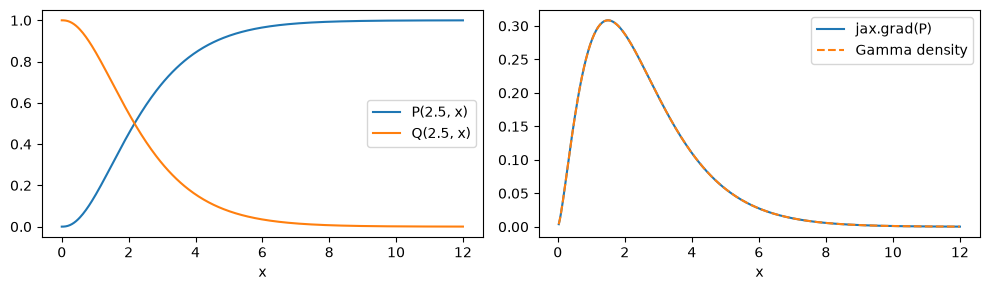

In [12]:
P = chebax.gammainc_frozen(2.5)
Q = chebax.gammaincc_frozen(2.5)

x = np.linspace(0.0, 12.0, 400)
print("max |P - scipy|:", np.max(np.abs(np.asarray(P(x)) - sps.gammainc(2.5, x))))
print("max |Q - scipy|:", np.max(np.abs(np.asarray(Q(x)) - sps.gammaincc(2.5, x))))

dP = jax.vmap(jax.grad(P))(x[1:])
print("max |dP/dx - density|:", np.max(np.abs(np.asarray(dP) - gamma_pdf(2.5, x[1:]))))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.plot(x, P(x), label="P(2.5, x)")
ax1.plot(x, Q(x), label="Q(2.5, x)")
ax1.set_xlabel("x")
ax1.legend()
ax2.plot(x[1:], dP, label="jax.grad(P)")
ax2.plot(x[1:], gamma_pdf(2.5, x[1:]), "--", label="Gamma density")
ax2.set_xlabel("x")
ax2.legend()
plt.tight_layout()

## One a per group: `pergroup`

Between one shared a and a fully per-element a sits the grouped case:
one shape per chain, per mixture component or per plate level, with the
grouping known in advance. `pergroup` wraps a function so each group gets
its own a. It rebuilds the tables once per group instead of once per
element, which pays off when groups are large (`experiments/07`).

In [13]:
group = np.repeat(np.arange(3), 4)  # 12 elements in 3 groups, fixed
x = jnp.linspace(0.5, 6.0, 12)
a_groups = jnp.asarray([0.8, 2.5, 7.0])

P_grouped = chebax.pergroup(chebax.gammainc, group)
print(np.asarray(P_grouped(a_groups, x)))
print("same as gammainc_array(a_groups[group], x):",
      np.allclose(P_grouped(a_groups, x), chebax.gammainc_array(a_groups[group], x), rtol=1e-13))

# the gradient in a_groups sums each group's elements
g = jax.grad(lambda ag: P_grouped(ag, x).sum())(a_groups)
g_arr = jax.grad(lambda ag: chebax.gammainc_array(ag[group], x).sum())(a_groups)
print("d/d a_groups:", np.asarray(g), " via gammainc_array:", np.asarray(g_arr))

[0.49919214 0.71857071 0.83806806 0.90571    0.58411981 0.69378108
 0.77935969 0.84376437 0.16894942 0.23781654 0.31396402 0.39369722]


same as gammainc_array(a_groups[group], x): True


d/d a_groups: [-1.47586922 -0.82328583 -0.52468334]  via gammainc_array: [-1.47586922 -0.82328583 -0.52468334]


## The inverses

`gammaincinv(a, p)` solves P(a, x) = p for x, and `gammainccinv(a, q)`
solves Q(a, x) = q, which keeps upper-tail quantiles resolved.
`chi2inv(k, p)` is the chi-square quantile at real degrees of freedom.
They follow the same naming as gammainc: the plain name takes one a or an
array, `gammaincinv_scalar` takes one traced a for the whole call (any
a > 0), and `gammaincinv_array` takes a per element (a >= 0.1). Their
gradients come from the implicit function theorem: dx/dp = 1/density,
and dx/da = -(dP/da)/density.

In [14]:
a0, p0 = 2.5, 0.3
x_p = chebax.gammaincinv(a0, p0)
print("gammaincinv(2.5, 0.3) =", float(x_p), " round trip P:", float(chebax.gammainc(a0, x_p)))
print("gammainccinv(2.5, 1e-200) =", float(chebax.gammainccinv(a0, 1e-200)))

dxda, dxdp = jax.grad(chebax.gammaincinv, argnums=(0, 1))(a0, p0)
dPda_at, dens = jax.grad(chebax.gammainc, argnums=(0, 1))(a0, x_p)
print(f"dx/dp = {float(dxdp):.10f}   1/density        = {float(1 / dens):.10f}")
print(f"dx/da = {float(dxda):.10f}   -(dP/da)/density = {float(-dPda_at / dens):.10f}")

gammaincinv(2.5, 0.3) = 1.4999540663799535  round trip P: 0.3


gammainccinv(2.5, 1e-200) = 469.46291311867463


E1102 17:20:59.050683 2465062 algebraic_simplifier.cc:10574] Algebraic simplifier is likely stuck in a circular simplification loop and ran for 50 runs on computation region_14.36


E1102 17:21:01.703939 2465062 algebraic_simplifier.cc:10574] Algebraic simplifier is likely stuck in a circular simplification loop and ran for 50 runs on computation region_7.25


dx/dp = 3.2429558361   1/density        = 3.2429558361
dx/da = 0.8177800118   -(dP/da)/density = 0.8177800118


With an array of a, the same call runs `gammaincinv_array`, one solve per
element on `gammainc_array`'s patches, and the derivatives are per
element too. Its derivatives are AD of the same ln P the solve inverted,
so they go to any order, d2x/da2 included; the scalar path would need
d2P/da2 from jax for that, and raises.

In [15]:
a_q = jnp.asarray([0.5, 2.5, 30.0, 1e4])
p_q = jnp.asarray([0.3, 0.9, 1e-20, 0.5])
x_q = chebax.gammaincinv(a_q, p_q)
print("x:           ", np.asarray(x_q))
print("round trip P:", np.asarray(chebax.gammainc(a_q, x_q)))
dxda_q = jax.grad(lambda a: chebax.gammaincinv(a, p_q).sum())(a_q)
d2xda2_q = jax.grad(lambda a: jax.grad(lambda a: chebax.gammaincinv(a, p_q).sum())(a).sum())(a_q)
print("dx/da:       ", np.asarray(dxda_q))
print("d2x/da2:     ", np.asarray(d2xda2_q))

x:            [7.42359309e-02 4.61817845e+00 2.84382024e+00 9.99966667e+03]
round trip P: [3.e-01 9.e-01 1.e-20 5.e-01]


dx/da:        [0.41662196 1.42991073 0.24788547 1.        ]
d2x/da2:      [ 9.00183157e-01 -9.57989872e-02  9.04755928e-03  3.95105227e-14]


## Precision

Everything above ran in float64 (`jax_enable_x64`). With jax's default
float32, every function here computes in float32, and the per-element
path then evaluates a smaller 7 x 7 block per patch. The measured worst
cases against mpmath, as recorded in the test files, are:

| | float64 | float32 |
|---|---|---|
| `log_gammainc_array` | 8.9e-16 | 4.5e-7 |
| `log_gammaincc_array` | 8.4e-15 | 2.9e-6 |

The error is measured as |error in ln F| / max(1, |ln F|): relative in F
where |ln F| ≤ 1, and relative in ln F in the deep tails.